# 公館活動熱點與公共垃圾桶查核

## tl;dr

2026 年 7 月官方檔共有 7,596,992 筆借還紀錄。公館 2 號出口直線 500 m 內，依 10 月站點快照配對得 42 站，其中非校區分類 15 站；前五站占這 15 站已觀測活動 65.8%。三處距 2026 清潔箱紀錄不到 50 m，應先查可用性與可達性。

**七月檔並不完整：7/11 無借車列，7/10 列數異常低。** 不報完整月需求，也不把活動當垃圾量。排除兩日或改用 300/700 m，前五站均相同。政府分工另見 `government/government-plan.md`，是提案而非機關承諾。

## Context & Methods

決策：優先到哪些站點周邊觀察投放服務，以及交給誰共同查核。分析前範圍、候選規則和停止條件在 `protocol.md`；日期品質問題後的追加檢查在 `quality-amendment.md`。

### Key Assumptions

- 中心 (121.53438, 25.01491)，球面直線 500 m；非步行距離、非官方服務半徑。
- 借與還各計一個站點活動事件；同一旅程兩端可重複計入，非人數。
- 七月站名對應十月快照，精確配對、保留未匹配與零觀測；無法排除跨期站名／站點變動。
- 七月暑假不是全年。端點時間只有小時精度；來源無旅程 ID，不把相同時站列任意去重。
- 校區分類站另計，不據來源分類推定土地權屬。垃圾、滿溢、路徑、清運與主管同意均未量測。

## Data

原始 ZIP 保存在交付資料夾 `raw/202607-youbike.zip`；可用 `GONGGUAN_ARCHIVE` 指定。來源與固定 SHA-256 見 `manifest.json`。其他輸入引用同包保留的 `../youbike-bin-screening-2026-10-18/inputs/`。每次重算都核對 digest；來源有變動時停止，不靜默覆寫。

在本目錄執行；Python 分析及圖表相依版本見 `requirements-analysis.txt`。

In [1]:
import os, json, contextlib, io
from pathlib import Path
from IPython.display import display, HTML, Image
from analyze import ROOT, main
from quality import main as check_quality
from validate import validate
manifest=json.loads((ROOT/'manifest.json').read_text())
portable=ROOT.parents[1]/'raw/202607-youbike.zip'
archive=Path(os.environ.get('GONGGUAN_ARCHIVE', str(portable if portable.exists() else manifest['trip_archive']['retained_archive'])))
assert archive.is_file(), 'Set GONGGUAN_ARCHIVE to the preserved original ZIP'
with contextlib.redirect_stdout(io.StringIO()):
    main(archive)
    check_quality()
receipt=validate(archive)
print('Raw rows:',receipt['raw_rows_independently_counted'])
print('Independent candidate reconciliation:',receipt['candidate_endpoints_reconciled'])
print('Source gap reproduced:',receipt['date_gap_reproduced'])

Raw rows: 7596992
Independent candidate reconciliation: 5
Source gap reproduced: True


## Results

### 優先查核站點

排名依既定的非校區分類站觀測活動；清冊距離不參與排序。記錄數不證明箱體實際存在、可用或可以不過街到達。

ID,站點,七月檔活動,最近清冊直線距離
C1,捷運公館站(2號出口),"91,340",40.9 m
C2,捷運公館站(3號出口),"40,477",121.3 m
C3,羅斯福新生南路口,"24,320",201.8 m
C4,羅斯福路四段108巷口,"23,738",17.8 m
C5,捷運公館站(1號出口),"18,651",5.6 m


Matplotlib is building the font cache; this may take a moment.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


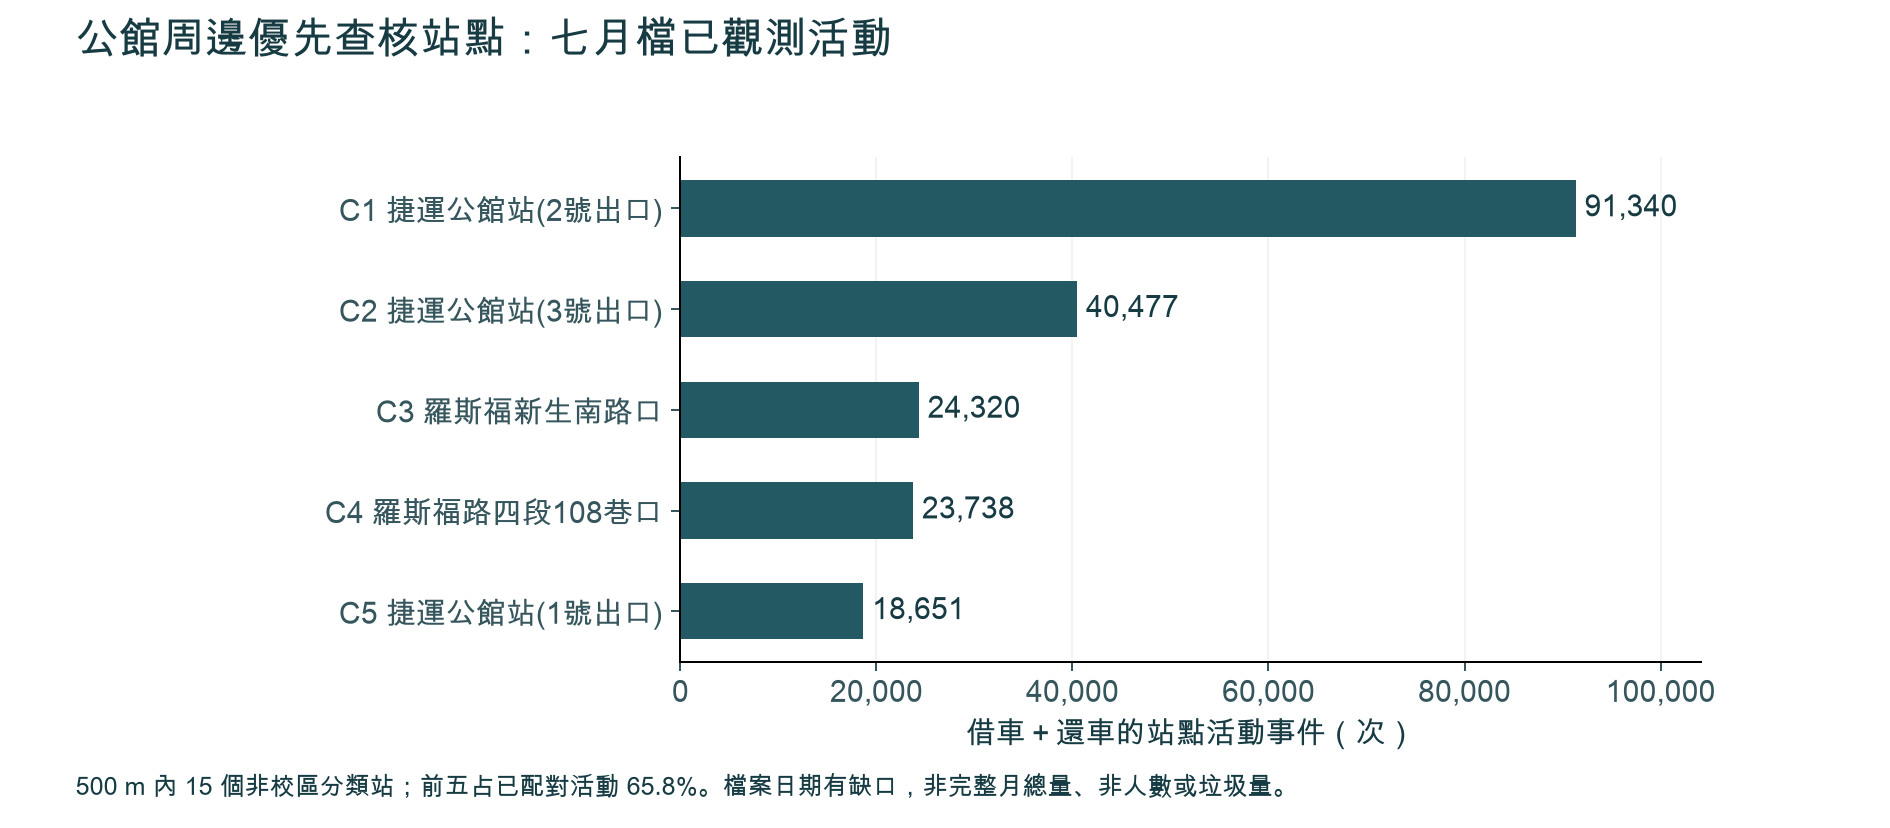

In [2]:
import html
s=json.loads((ROOT/'results/summary.json').read_text())
rows=''.join('<tr>'+''.join(f'<td>{html.escape(str(v))}</td>' for v in [r['candidate_id'],r['name'],f"{r['events']:,}",f"{r['bins2026_nearest_m']:.1f} m"])+'</tr>' for r in s['shortlist'])
display(HTML('<table><tr><th>ID</th><th>站點</th><th>七月檔活動</th><th>最近清冊直線距離</th></tr>'+rows+'</table>'))
from figures import create_figures
figure_dir=create_figures()
display(Image(filename=str(figure_dir/'activity-ranking.png')))

### 分時觀察與空間線索

日期品質敏感度排除 7/10、7/11，使用 22 個平日及 7 個週末日；這不證明其餘日期完整。前五站合計在 18–19 時最高：平日每日期平均 758.9 次、週末 562.1 次。規劃 10–11 時作對照，不推論因果。

座標圖只表達位置關係，沒有道路底圖或實走路線。

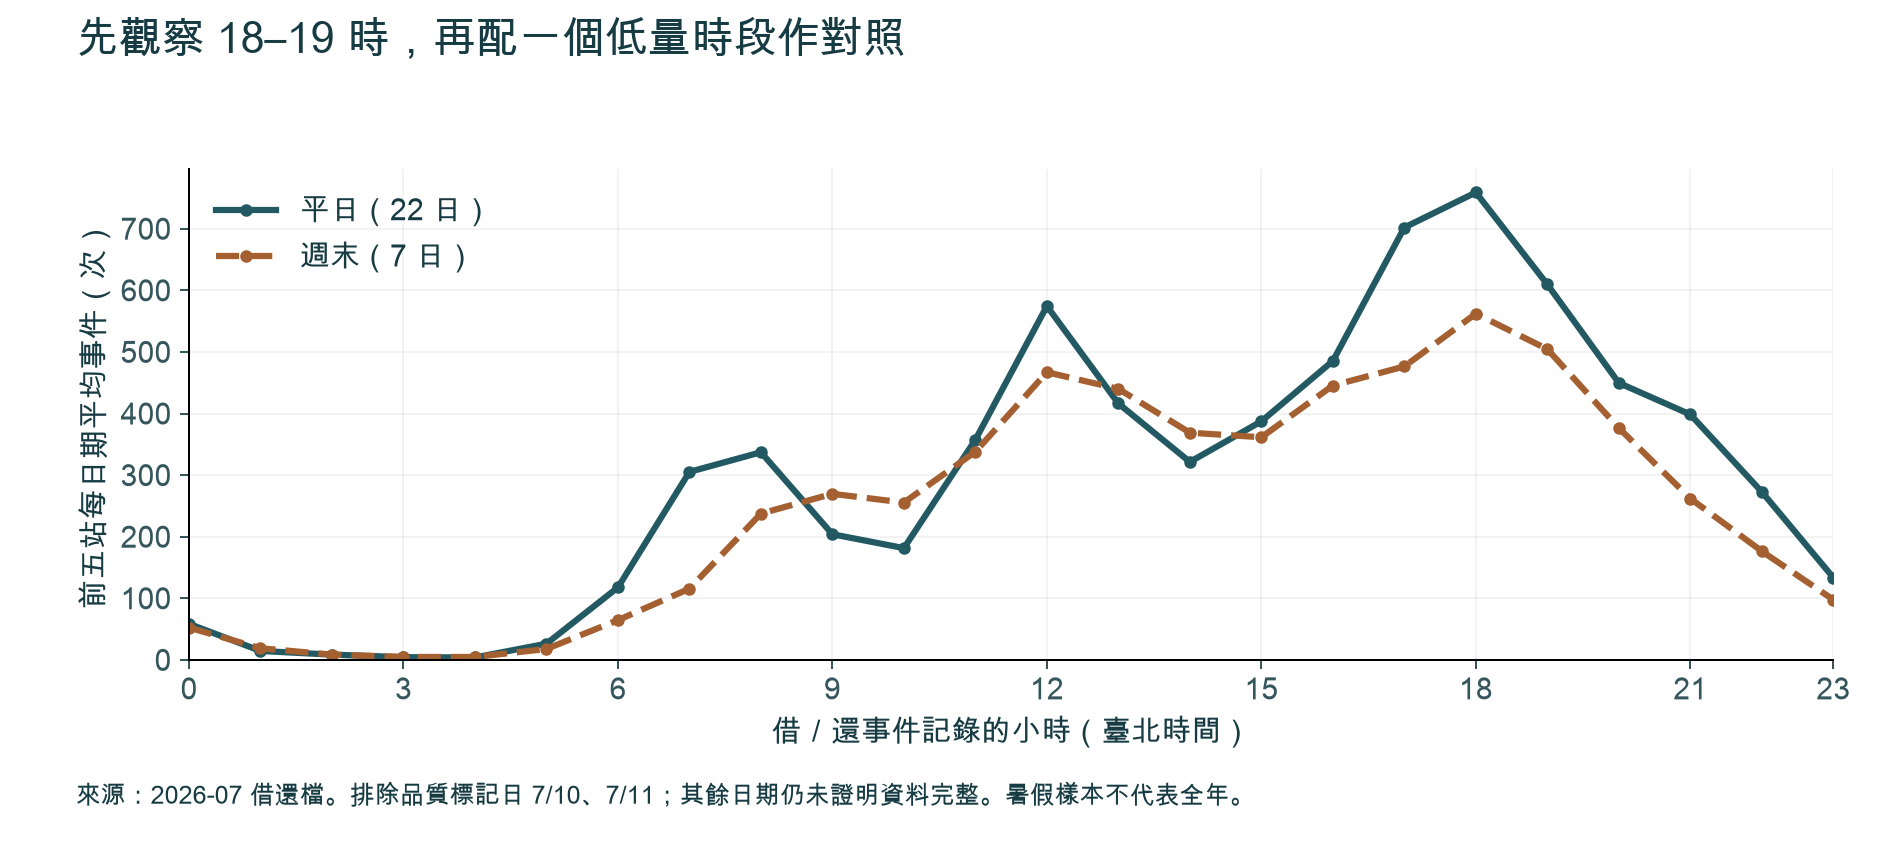

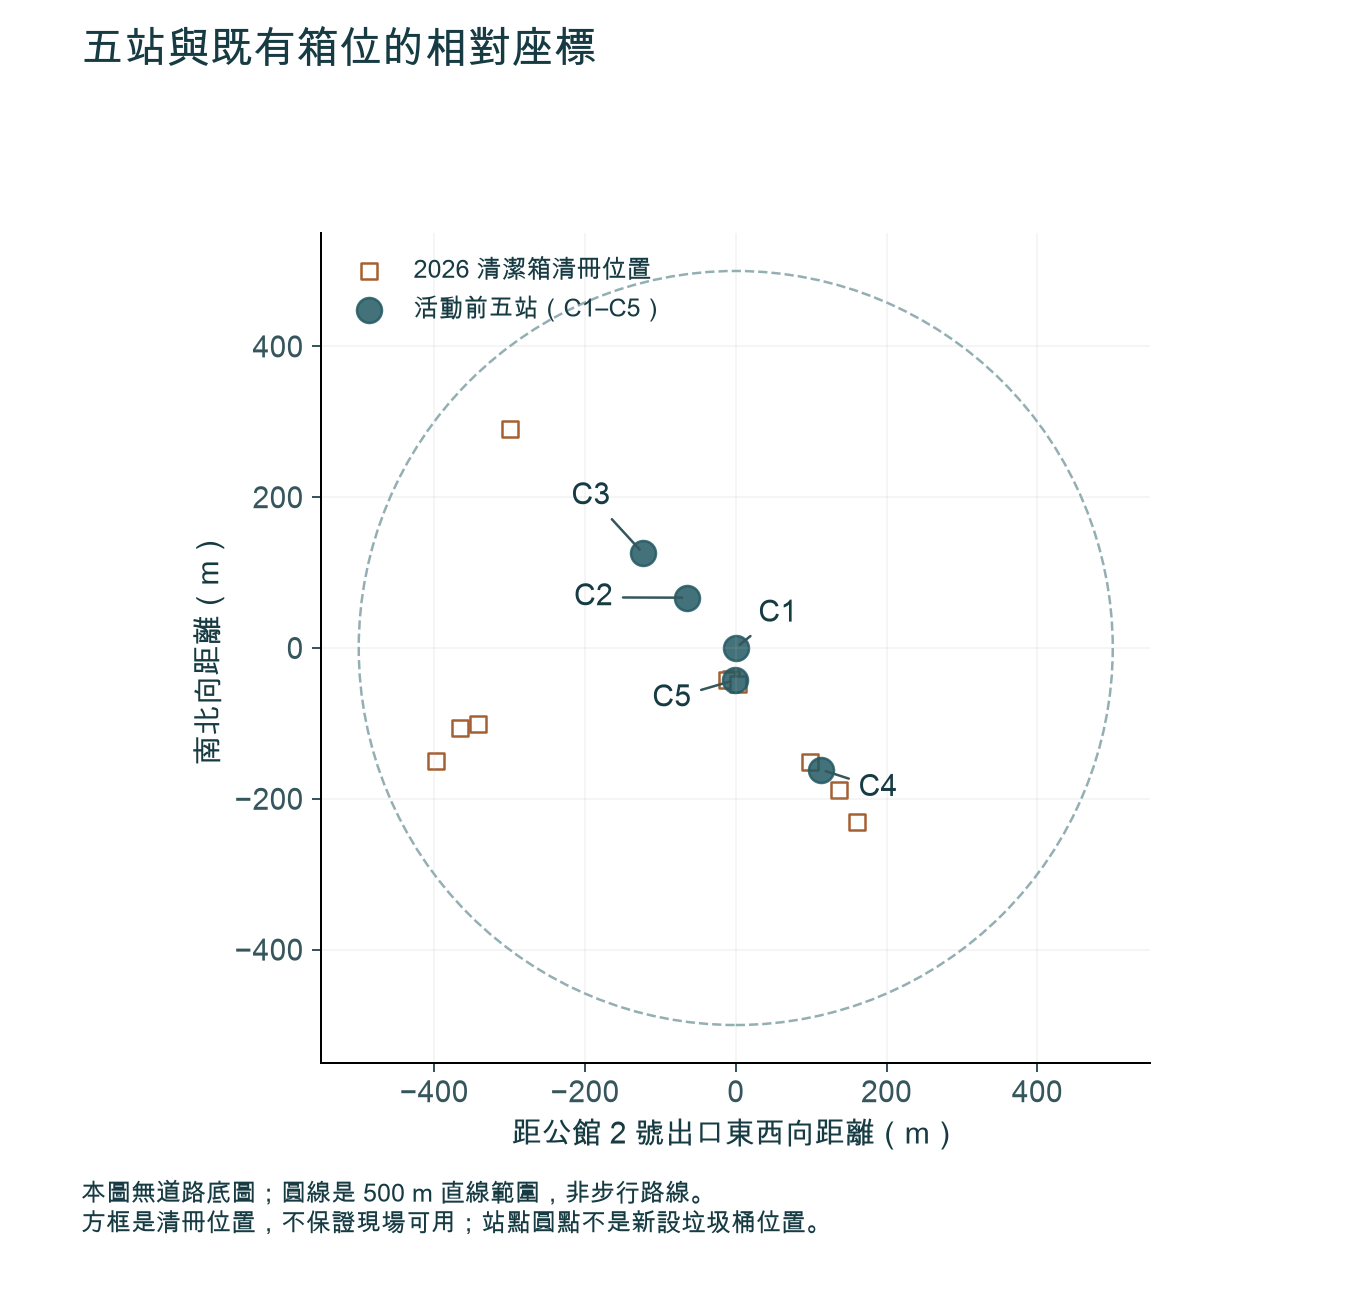

In [3]:
display(Image(filename=str(figure_dir/'activity-hours.png')))
display(Image(filename=str(figure_dir/'station-context.png')))

### 品質與敏感度

站點屬性是 2026-10-18 快照，街道清冊是 2026-09-30，場所清冊是 2026-08-18。公車 2021 站位檔未附投影定義且座標值是經緯度形式；只保留歷史線索，不納入排名。沒有逐站公車上下車量，不做雙運具人流合計。

In [4]:
q=json.loads((ROOT/'results/quality.json').read_text())
for r in s['sensitivity']:
    print(r['radius_m'], 'm:',r['eligible_stations'],'non-campus stations;',r['shared_with_500m'],'of 5 unchanged')
print('Flagged dates:',q['flagged_dates'])
print('Excluding flagged dates, same five:',q['same_top5_members'])
print('Unmatched borrow endpoints:',s['totals']['borrow_unmatched'])
print('Unmatched return endpoints:',s['totals']['return_unmatched'])
print('No matched activity is UNKNOWN, not zero demand:',s['no_observation_500m'])

300 m: 9 non-campus stations; 5 of 5 unchanged
500 m: 15 non-campus stations; 5 of 5 unchanged
700 m: 26 non-campus stations; 5 of 5 unchanged
Flagged dates: ['2026-07-10', '2026-07-11']
Excluding flagged dates, same five: True
Unmatched borrow endpoints: 22230
Unmatched return endpoints: 133671
No matched activity is UNKNOWN, not zero demand: ['臺大普通教學館東側']


## Takeaways

1. 先查 C1 公館 2 號出口，並用 C4 108 巷口、C5 1 號出口檢驗「附近有桶卻不便使用」；三處距清冊位置均小於 50 m。
2. C2 3 號出口、C3 羅斯福新生南路口查實際步行、過街及舊清冊線索。較遠的現行清冊位置不能證明缺桶或撤桶。
3. 建議 2 個平日＋1 個週末、每站於 10–11 與 18–19 時窗各 15 分鐘，共 30 站次。這是尚未執行的最小基線，需先完成現地安全與場地條件確認。
4. 以環保局作提案統籌窗口，清潔區隊、交通單位與實際場地管理者分工確認；詳見政府工作包。未確認權責、無障礙或清運承接的點不進入設點試辦。

本成果完成的是可重跑的桌面分析與分工提案；未完成現勘、機關核准、配置工具或成效實驗。